## <font color="purple">Descriptive Statistics and Data Visualization</font> 
### <font color="blue">(Titanic Dataset (Part 2): Visual Storytelling)</font> 
#### <font color="green">Visualization with Matplotlib/Seaborn - Titanic Dataset.</font>
 **-- Dr. Meenakshi Nerolu**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

This is the continuation of what we have done in `Titanic_dataset_Part1` & `Titanic_dataset_Part1b`where we have cleaned the data. 

In [3]:
## LOAD TITANIC DATASET using Seaborn
df = pd.read_csv("Titanic_dataset.csv")

In [4]:
df_new=df.copy()

In [5]:
df_new['Pclass'].dtype

dtype('int64')

In [6]:
df_new['Pclass']=df_new['Pclass'].astype('category')
df_new['Pclass']=df_new['Pclass'].map ({1:'First', 2: 'Second', 3: 'Third'})


In [7]:
# Fill missing Age values based on the median age for each Pclass and Sex group
df_new['Age'] = df_new.groupby(['Pclass', 'Sex'],observed=True)['Age'].transform(lambda x: x.fillna(x.median()))
#Handling missing value for Embarked column 
df_new['Embarked'] = df_new['Embarked'].fillna(df_new['Embarked'].mode()[0])

# Before deleting Cabin column we will copy the df_new into another dataframe
df_filtered=df_new.copy()
df_filtered.drop(columns=['Cabin'], inplace=True)

# Copy the entire cleaned dataframe to df_cleaned and use it for further analysis
df_cleaned=df_filtered.copy()
df_cleaned

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,Third,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,First,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,Third,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,First,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,Third,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S
...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,Second,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,S
887,888,1,First,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,S
888,889,0,Third,"Johnston, Miss. Catherine Helen ""Carrie""",female,21.5,1,2,W./C. 6607,23.4500,S
889,890,1,First,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C


In [8]:
#Survival rate by gender
# Write your code here
survival_rate = df_cleaned.groupby("Sex")["Survived"].mean() * 100
survival_rate

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

In [9]:
# survival rate by passenger class
# Write your code here
survival_rate_by_passenger_class = df_cleaned.groupby("Pclass")["Survived"].mean() * 100
survival_rate_by_passenger_class

Pclass
First     62.962963
Second    47.282609
Third     24.236253
Name: Survived, dtype: float64

In [10]:
#Feature Engineering: Family Size, Isalone, agegroup
df_cleaned['FamilySize'] = df_cleaned['SibSp'] + df_cleaned['Parch'] + 1
df_cleaned['IsAlone'] = (df_cleaned['FamilySize'] == 1).astype(int)
def classify_age(age):
    if pd.isnull(age):
        return 'Unknown'
    elif age < 13:
        return 'Child'
    elif age < 18:
        return 'Teen'
    elif age < 35:
        return 'Young Adult'
    elif age < 60:
        return 'Adult'
    else:
        return 'Senior'

df_cleaned = df_cleaned.copy()
df_cleaned['AgeGroup'] = df_cleaned['Age'].apply(classify_age)

df_cleaned['AgeGroup']=df_cleaned['Age'].apply(classify_age)
df_cleaned['FamilySize']=df_cleaned['SibSp']+df_cleaned['Parch']+1
df_cleaned['IsAlone']=(df_cleaned['FamilySize']==1).astype(int)


In [11]:
df_cleaned.to_csv('Titanic_cleaned_data.csv')

### **Age Distribution (Historgram)**

A histogram shows how the ages are distributed across passengers.  
It helps us answer questions such as:

- Are most passengers younger or older?
- Is the distribution symmetric or skewed?
- Are there visible gaps or clusters?


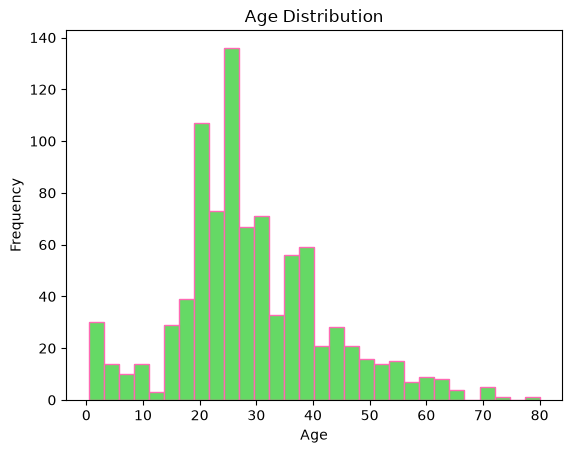

In [12]:
# Code
sns.histplot(df_cleaned["Age"], bins=30, edgecolor="hotpink", color="limegreen")
plt.ylabel("Frequency")
plt.title("Age Distribution")
plt.show()

### **Survival Counts by Age Group (Count Plot)**
This graph uses a countplot.
That means it shows how many passengers fall into each AgeGroup and survival category.

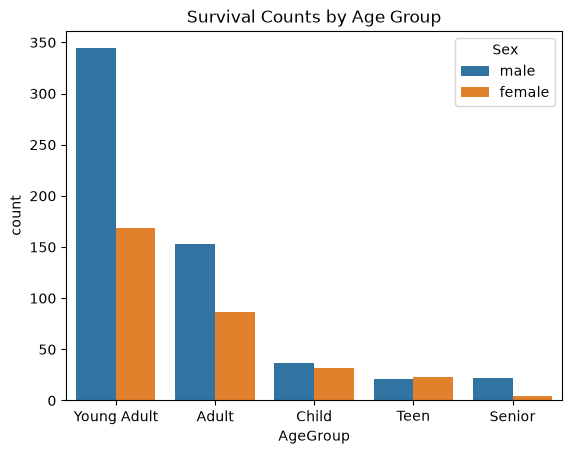

In [13]:
# Seaborn
sns.countplot(df_cleaned, x="AgeGroup", hue="Sex")
plt.title("Survival Counts by Age Group")
plt.savefig("Survival_age.png")
plt.show()

<Axes: xlabel='AgeGroup'>

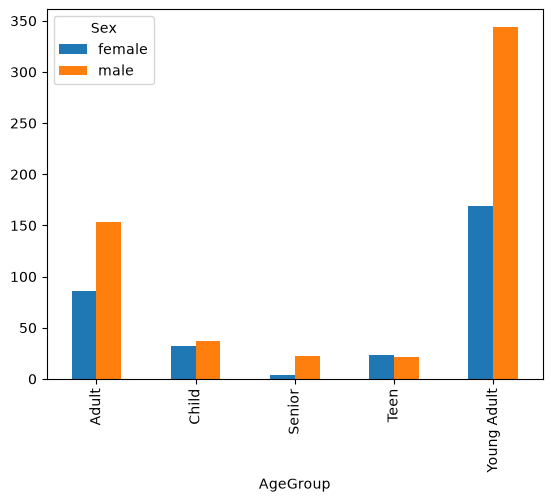

In [14]:
# Matplotlib
surv_count_agegroup = df_cleaned.groupby("AgeGroup")["Sex"].value_counts().unstack(fill_value=0)
surv_count_agegroup.plot(kind="bar")

### **Survival Counts by Gender**


<Axes: >

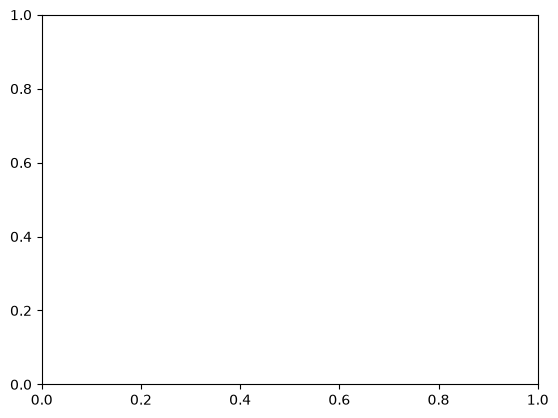

In [15]:
# Seaborn
survival_count_by_gender = df_cleaned.groupby("Sex")["Survived"].count()
sns.barplot()

---
#### **Survival Rate by Age Group, Gender and Pclass (Bar Plot)**

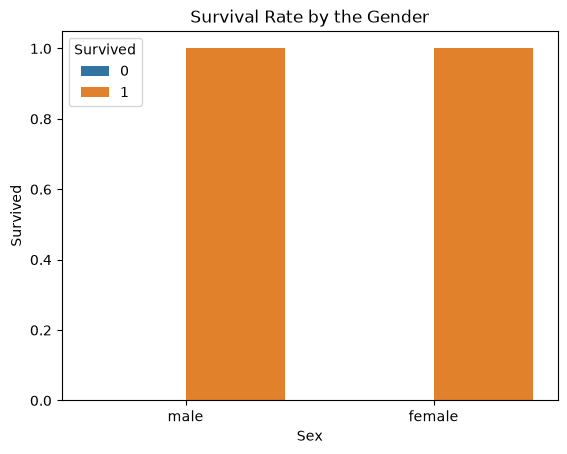

In [16]:
#Seaborn
sns.barplot(df_cleaned, x="Sex", y="Survived", hue="Survived")
plt.title("Survival Rate by the Gender")
plt.show()

<Axes: xlabel='AgeGroup'>

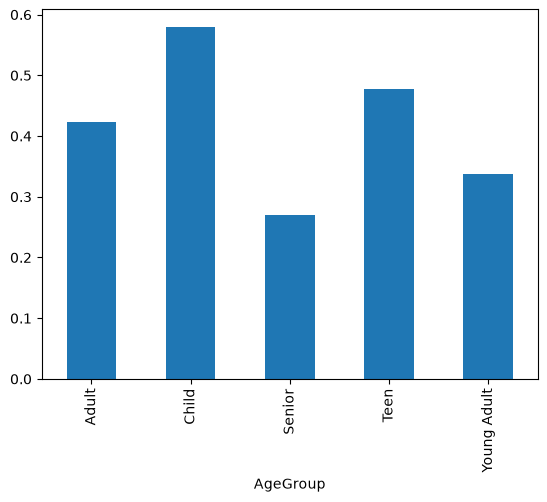

In [17]:
# Matplotlib
surv_agegroup = df_cleaned.groupby("AgeGroup")["Survived"].mean()
surv_agegroup.plot(kind="bar")

<Axes: xlabel='AgeGroup', ylabel='Survived'>

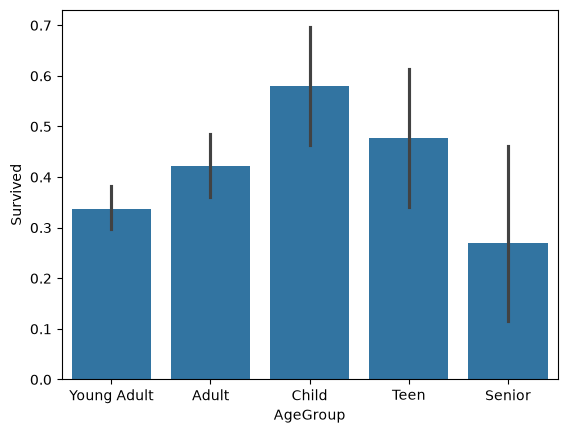

In [18]:
sns.barplot(df_cleaned, x="AgeGroup", y="Survived")

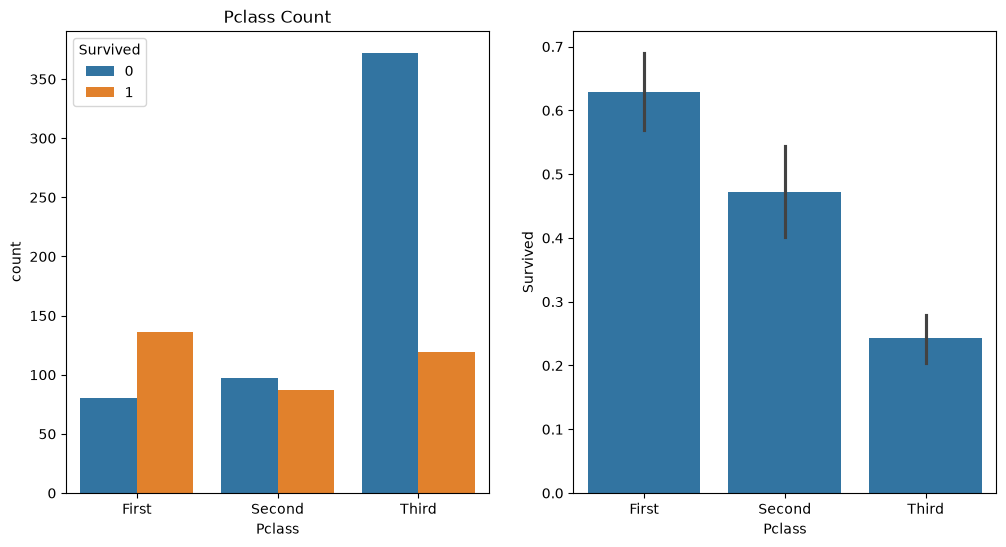

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
sns.countplot(df_cleaned, x="Pclass", hue="Survived", ax=axes[0])
axes[0].set_title("Pclass Count")
sns.barplot(df_cleaned, x="Pclass", y="Survived")
plt.show()

### **Fare Distribution by Passenger Class (Box Plot)**
This box plot compares fare distributions across passenger classes.


<Axes: xlabel='Pclass', ylabel='Fare'>

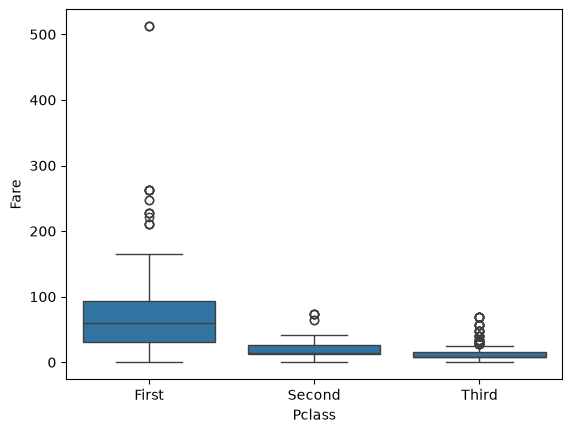

In [20]:
sns.boxplot(df_cleaned, x="Pclass", y="Fare")

# Proportion of survival - Piechart

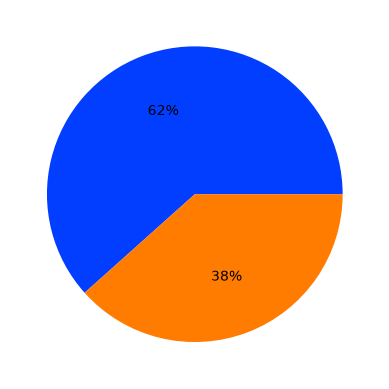

In [21]:
survival_proportion = df_cleaned["Survived"].value_counts()
colors = sns.color_palette('bright')
plt.pie(survival_proportion, colors=colors, autopct="%.0f%%")
plt.show()

### **Survival Rate by Traveling Alone or With Others**

Text(0.5, 1.0, 'Age Distribution')

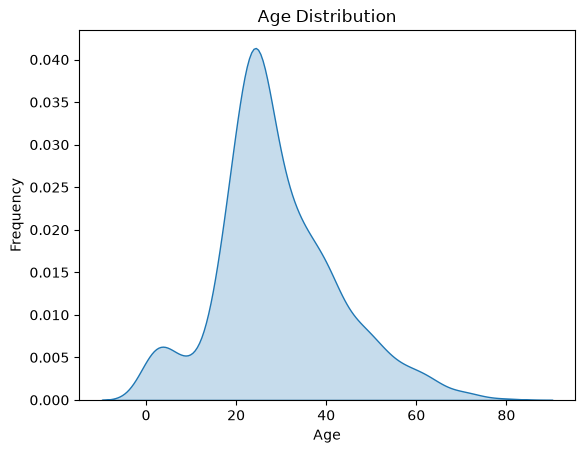

In [22]:
sns.kdeplot(df_cleaned["Age"], fill=True)
plt.ylabel("Frequency")
plt.title("Age Distribution")
#plt.show()

# Facet Grid

NameError: name 'facet_grid' is not defined

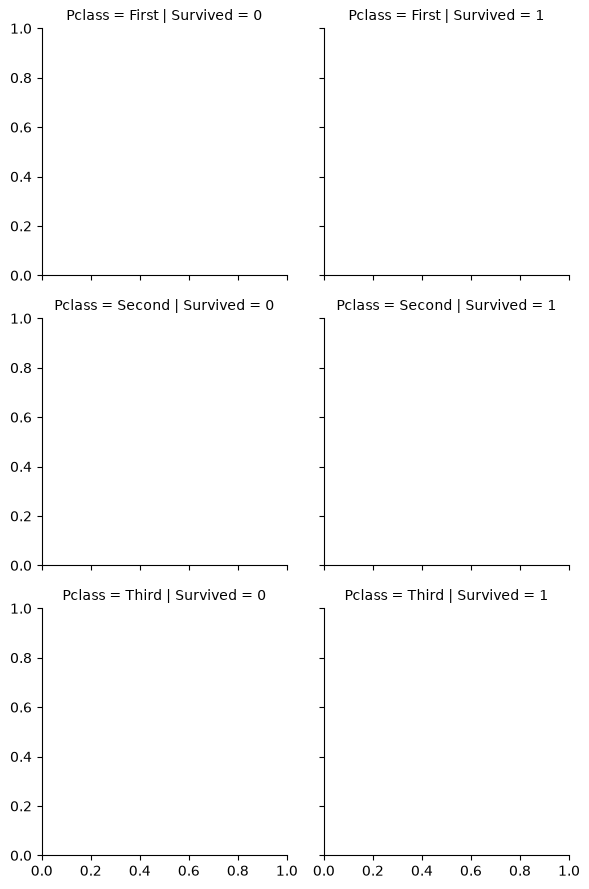

In [23]:
sns.FacetGrid(df_cleaned, col="Survived", row="Pclass")
facet_grid.map

In [30]:
import plotly.express as px

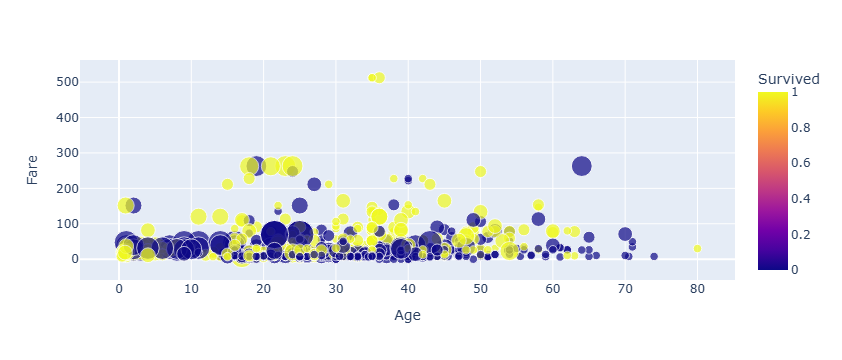

In [34]:
fig = px.scatter(df_cleaned, x="Age", y="Fare", color="Survived", hover_data=["Sex", "Pclass"], size="FamilySize")
fig.write_html("age_fare.html")
fig.show()